# Final Project: Adult Data Set

---

## Step 1

1. Frame the problem and look at the big picture
    * Define the objective in business terms.

The goal is to **predict whether an adult's annual income exceeds $50,000** using demographic and employment-related attributes from the 1994 U.S. Census Bureau database.
In business terms, this predictive model could support:

*   **Marketing**: Identifying high-income individuals for targeted campaigns.
*   **Public policy**: Understanding socioeconomic factors associated with higher income.
*   **Financial services**: Pre-screening candidates for certain financial products.
*   **Workforce or labor analytics**: Better understanding how education, work hours, and job type relate to income.

The objective: **Develop a supervised classification model that predicts >50K vs. ≤50K with high accuracy and fairness.**

1. continued...
    * How will your solution be used?

The solution will be used to:

* Automatically **classify individuals' income categories** based on input features.
* Provide **insights into which demographic attributes most influence income**.
* Allow end-users (analysts or automated systems) to input new person-records and receive a predicted income bracket.
* Potentially be deployed in dashboards, reports, or as an API for real-time use.


1. continued...
    * List the assumptions you have made so far.

* The dataset is representative of real socioeconomic patterns (though it is from 1994 and may not reflect current trends).
* Missing values indicated by '?' can be reliably imputed or removed.
* Categorical attributes can be encoded without losing meaning.
* The target variable (income) is correctly labeled and balanced enough for modeling.
* The relationships captured in the 1994 Census still illustrate general concepts about how attributes relate to income.
* Sensitive attributes (e.g., race, sex) will be handled carefully to ensure fairness and avoid unintended bias.
* The Adult dataset is sufficiently large (48,842 rows) for training and testing.



---



## Step 2

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing
from numpy.core.fromnumeric import diagonal

/tmp/ipython-input-3127374247.py:6: DeprecationWarning: numpy.core.fromnumeric is deprecated and has been renamed to numpy._core.fromnumeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.fromnumeric.diagonal.
  from numpy.core.fromnumeric import diagonal


2. Get the data and explore the data to gain insights
    * a. Create a workspace to store the data.

In [2]:
df_raw = pd.read_csv('adultAll.csv')

2. continued...
    *   b. Create a copy of the data for exploration (sampling it down to a manageable size is necessary)

In [3]:
df = df_raw.copy()

2. continued...
    *   c. Study each attributes and its characteristics

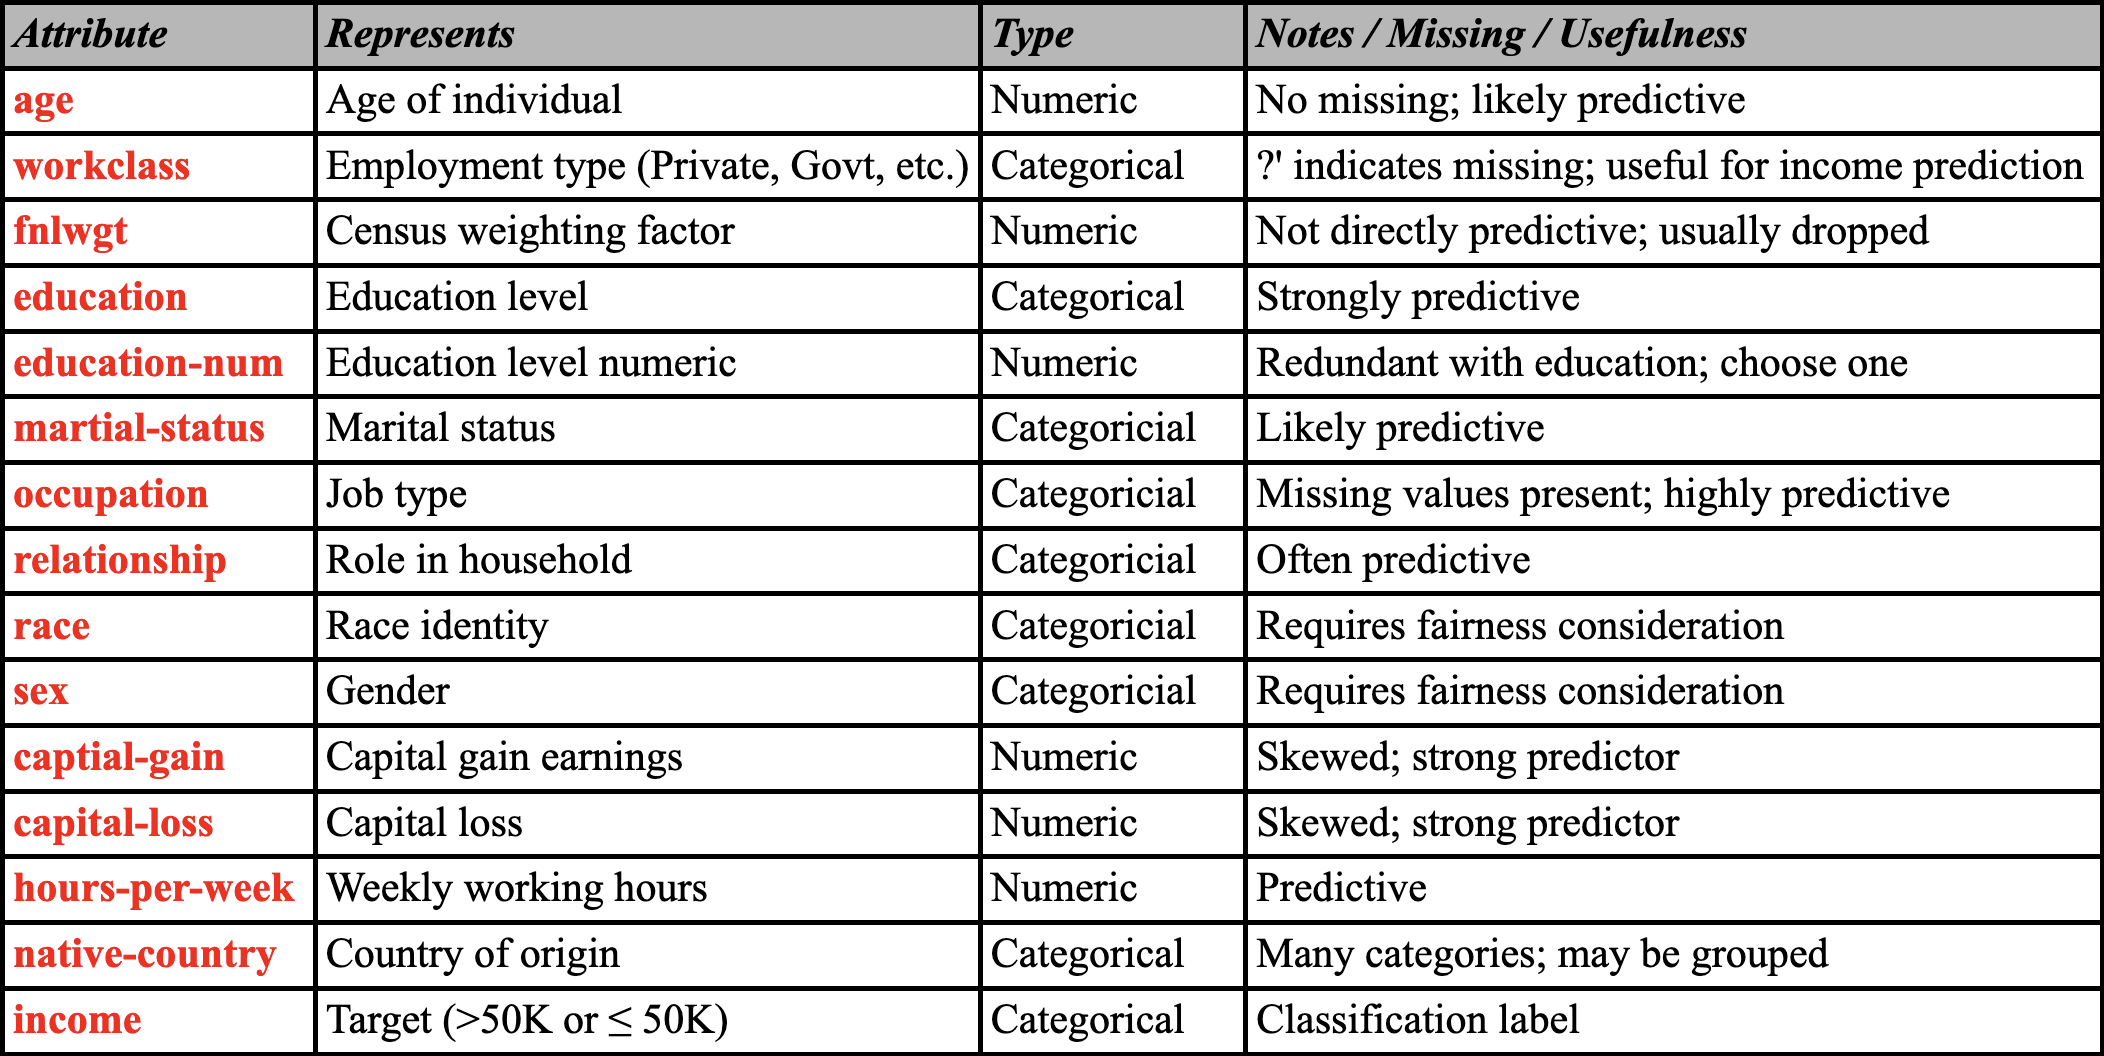

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  Income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [5]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [6]:
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
48838,64,?,321403,HS-grad,9,Widowed,?,Other-relative,Black,Male,0,0,40,United-States,<=50K.
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.
48841,35,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,>50K.


In [7]:
df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
df = df.replace("?", np.nan)

In [8]:
df.isna().mean() * 100

,0
age,0.000000
workclass,5.730724
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,5.751198
relationship,0.000000
race,0.000000
sex,0.000000


2. continued...
    *   d. Based on the availability of attributes and identified business problem, frame your problem as supervised or unsupervised learning, decide data mining algorithms to adopt.

Because the dataset includes a known target variable (Income, labeled as >50K or <=50K), this is a:

* **Supervised learning** problem
* More specifically, a **binary classification** task

Based on the attributes in the Adult dataset (a mix of numerical and categorical features), the following algorithms are appropriate:

* **Naive Bayes Classifier**
    * A simple probabilistic classifier
    * Provides a fast, interpretable baseline
    * Works well as an initial model for comparison
* **K-Nearest Neighbors (KNN)**
    * A distance-based classifier that uses similarity between instances
    * Takes advantage of the feature scaling performed in preprocessing
    * Useful to see how a non-parametric method performs on this dataset
* **Decision Tree Classifier**
    * A tree-based method that recursively splits the data
    * Can capture non-linear relationships and interactions between attributes
    * Easy to interpret visually and provides insight into which features are most important



---



## Step 3

3. Prepare the data to better expose the underlying data patterns to data mining algorithms.
    *   a. Work on copies of the data.

In [9]:
df_clean = df.copy()

3. continued...
    *   b. Data cleaning.

### age

In [10]:
df_clean['age'].describe()

,age
count,48842.000000
mean,38.643585
std,13.710510
min,17.000000
25%,28.000000
50%,37.000000
75%,48.000000
max,90.000000


<Axes: ylabel='Density'>

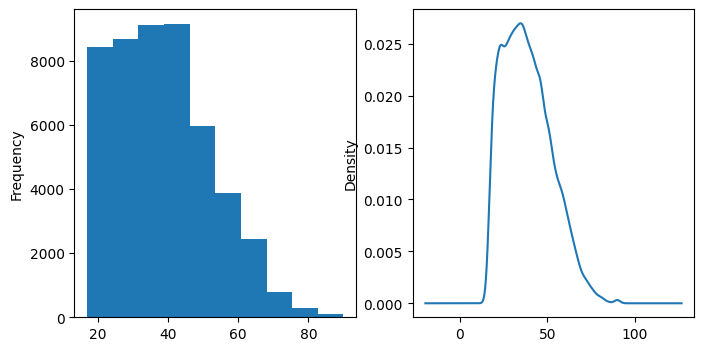

In [11]:
%matplotlib inline

fig, ax = plt.subplots(1,2, figsize=(8,4))
df_clean['age'].plot.hist(bins=10, ax=ax[0])
df_clean['age'].plot.density(ax=ax[1])

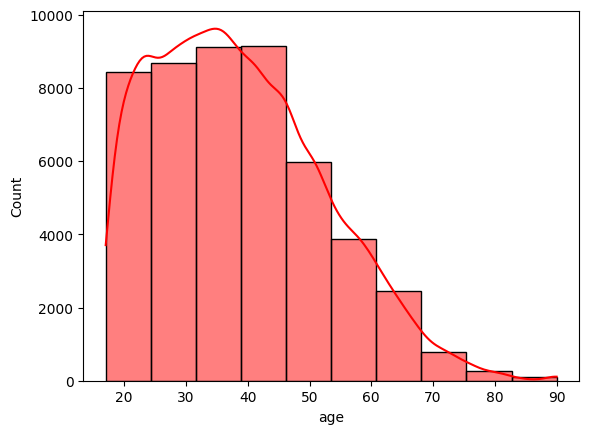

In [12]:
sns_plot= sns.histplot(df_clean['age'], bins=10, color='red', kde=True)

In [13]:
def check_outliers(x, factor):
  q25 = x.quantile(.25)
  q75 = x.quantile(.75)
  IQR = q75-q25
  l = q25 - IQR*factor
  u = q75 + IQR*factor
  return l, u

In [14]:
lower, upper = check_outliers(df_clean['age'],2)
print(f'lower = {lower}, upper = {upper}')

lower = -12.0, upper = 88.0


In [15]:
mask_lower = df_clean['age']< lower
mask_lower.sum()

np.int64(0)

In [16]:
mask_upper = df_clean['age']>upper
mask_upper.sum()

np.int64(57)

In [17]:
df_clean[mask_upper]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income
222,90,Private,51744,HS-grad,9,Never-married,Other-service,Not-in-family,Black,Male,0,2206,40,United-States,<=50K
1040,90,Private,137018,HS-grad,9,Never-married,Other-service,Not-in-family,White,Female,0,0,40,United-States,<=50K
1935,90,Private,221832,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,<=50K
2303,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
2891,90,Private,171956,Some-college,10,Separated,Adm-clerical,Own-child,White,Female,0,0,40,Puerto-Rico,<=50K
4070,90,Private,313986,11th,7,Never-married,Handlers-cleaners,Own-child,White,Male,0,0,40,United-States,<=50K
4109,90,NaN,256514,Bachelors,13,Widowed,NaN,Other-relative,White,Female,991,0,10,United-States,<=50K
5104,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
5272,90,Private,141758,9th,5,Never-married,Adm-clerical,Not-in-family,White,Female,0,0,40,United-States,<=50K
5370,90,Local-gov,227796,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,20051,0,60,United-States,>50K


*Replacing outliers:*

In [18]:
# Replacing outliers because extreme ages are rare but still valid and replacing the outliers with closer boundaries preserves data

In [19]:
df_clean['replace_age']=df_clean['age'].map(lambda x: upper if x>upper else lower if x<lower else x)

<Axes: >

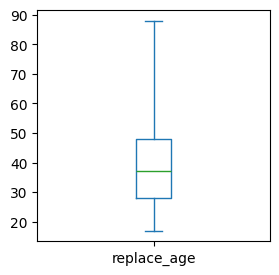

In [20]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['replace_age'].plot.box(whis=2)

### workclass

In [21]:
df_clean['workclass'].unique()

array(['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov',
       'Local-gov', nan, 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

In [22]:
df_clean['workclass'].value_counts()

,count
workclass,
Private,33906
Self-emp-not-inc,3862
Local-gov,3136
State-gov,1981
Self-emp-inc,1695
Federal-gov,1432
Without-pay,21
Never-worked,10


<Axes: xlabel='workclass'>

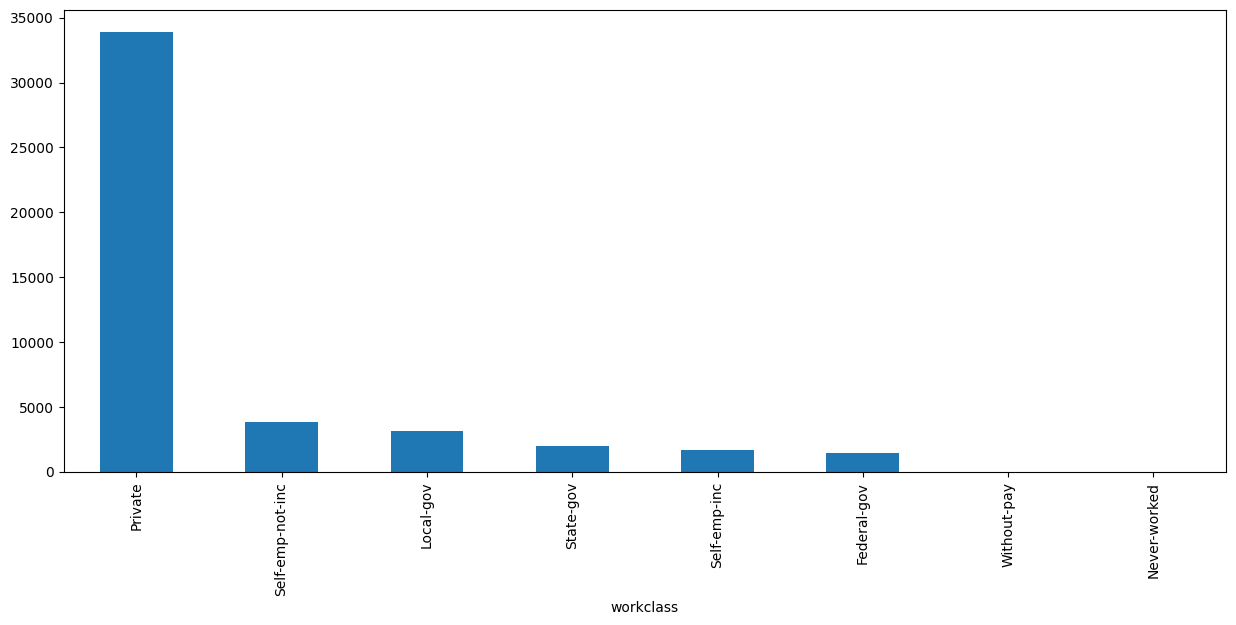

In [23]:
df_clean['workclass'].value_counts().plot(kind='bar', figsize=(15, 6))

### fnlwgt

<Axes: >

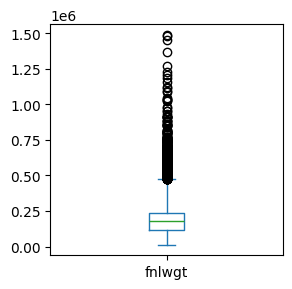

In [24]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['fnlwgt'].plot.box(whis=2)

In [25]:
df_clean['fnlwgt'].describe()

,fnlwgt
count,4.884200e+04
mean,1.896641e+05
std,1.056040e+05
min,1.228500e+04
25%,1.175505e+05
50%,1.781445e+05
75%,2.376420e+05
max,1.490400e+06


<Axes: ylabel='Density'>

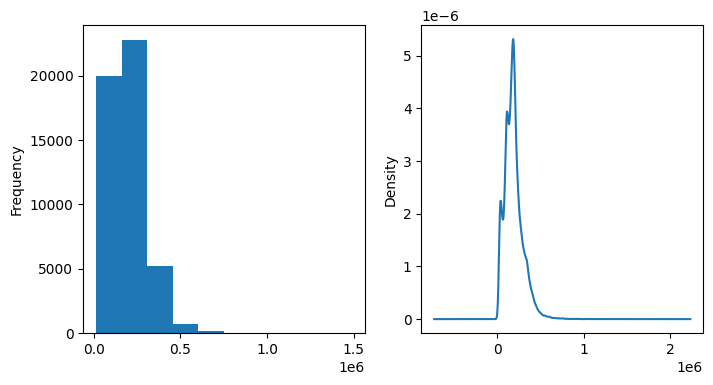

In [26]:
fig, ax = plt.subplots(1,2, figsize=(8,4))
df_clean['fnlwgt'].plot.hist(bins=10, ax=ax[0])
df_clean['fnlwgt'].plot.density(ax=ax[1])

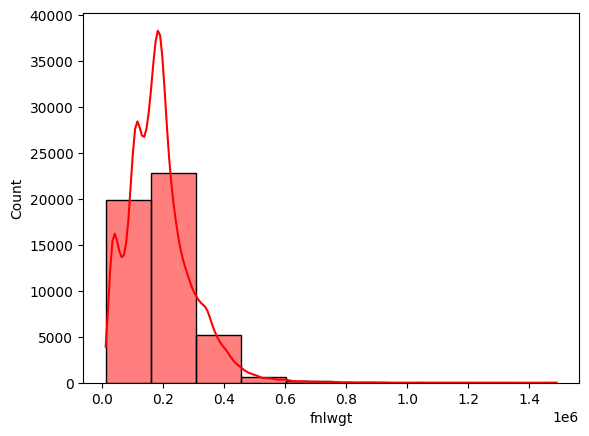

In [27]:
sns_plot= sns.histplot(df_clean['fnlwgt'], bins=10, color='red', kde=True)

In [28]:
def check_outliers(x, factor):
  q25 = x.quantile(.25)
  q75 = x.quantile(.75)
  IQR = q75-q25
  l = q25 - IQR*factor
  u = q75 + IQR*factor
  return l, u

In [29]:
lower, upper = check_outliers(df_clean['fnlwgt'],2)
print(f'lower = {lower}, upper={upper}')

lower = -122632.5, upper=477825.0


In [30]:
mask_lower = df_clean['fnlwgt']< lower
mask_lower.sum()

np.int64(0)

In [31]:
mask_upper = df_clean['fnlwgt']>upper
mask_upper.sum()

np.int64(694)

In [32]:
df_clean[mask_upper]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income,replace_age
37,19,Private,544091,HS-grad,9,Married-AF-spouse,Adm-clerical,Wife,White,Female,0,0,25,United-States,<=50K,19.0
40,31,Private,507875,9th,5,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,43,United-States,<=50K,31.0
157,71,Self-emp-not-inc,494223,Some-college,10,Separated,Sales,Unmarried,Black,Male,0,1816,2,United-States,<=50K,71.0
177,34,Private,483777,HS-grad,9,Never-married,Handlers-cleaners,Not-in-family,Black,Male,0,0,40,United-States,<=50K,34.0
182,30,Private,633742,Some-college,10,Never-married,Craft-repair,Not-in-family,Black,Male,0,0,45,United-States,<=50K,30.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48458,18,Private,618808,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,40,United-States,<=50K.,18.0
48466,73,Private,573446,Some-college,10,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,15,United-States,<=50K.,73.0
48574,37,Self-emp-not-inc,504871,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K.,37.0
48578,59,Private,532969,HS-grad,9,Married-civ-spouse,Other-service,Other-relative,White,Male,0,0,40,Nicaragua,<=50K.,59.0


*Removing column:*

In [33]:
# Dropping column because it is not a real feature but rather sampling weight

In [34]:
df_clean = df_clean.drop(columns=['fnlwgt'])

### education

In [35]:
df_clean['education'].unique()

array(['Bachelors', 'HS-grad', '11th', 'Masters', '9th', 'Some-college',
       'Assoc-acdm', 'Assoc-voc', '7th-8th', 'Doctorate', 'Prof-school',
       '5th-6th', '10th', '1st-4th', 'Preschool', '12th'], dtype=object)

In [36]:
df_clean['education'].value_counts()

,count
education,
HS-grad,15784
Some-college,10878
Bachelors,8025
Masters,2657
Assoc-voc,2061
11th,1812
Assoc-acdm,1601
10th,1389
7th-8th,955


<Axes: xlabel='education'>

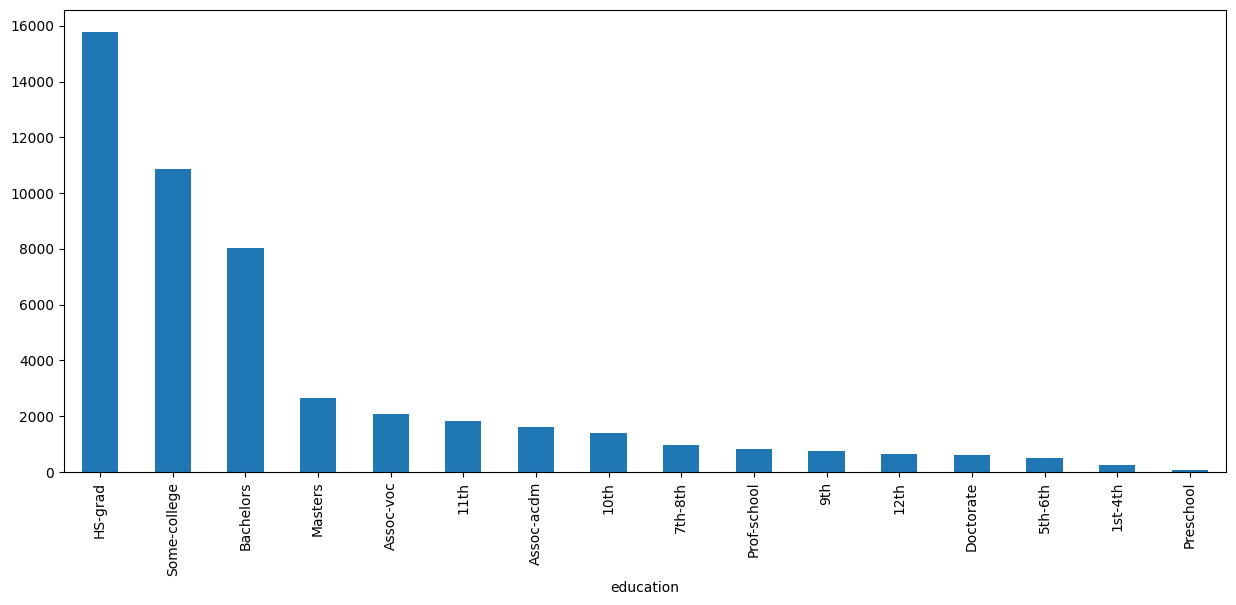

In [37]:
df_clean['education'].value_counts().plot(kind='bar', figsize=(15, 6))

### education-num

<Axes: >

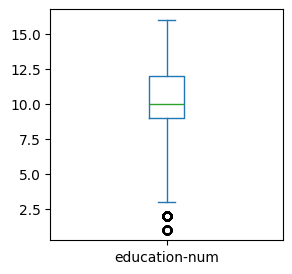

In [38]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['education-num'].plot.box(whis=2)

In [39]:
df_clean['education-num'].describe()

,education-num
count,48842.000000
mean,10.078089
std,2.570973
min,1.000000
25%,9.000000
50%,10.000000
75%,12.000000
max,16.000000


<Axes: ylabel='Density'>

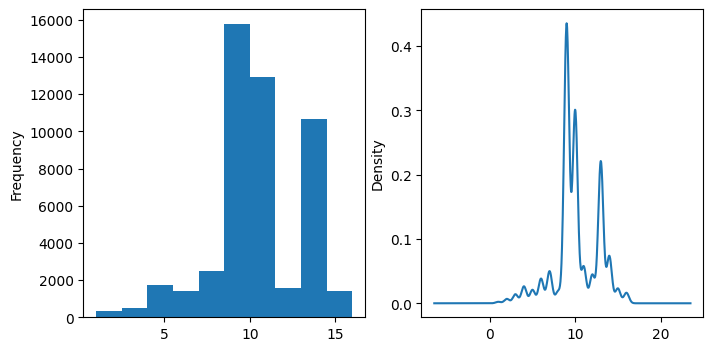

In [40]:
fig, ax = plt.subplots(1,2, figsize=(8,4))
df_clean['education-num'].plot.hist(bins=10, ax=ax[0])
df_clean['education-num'].plot.density(ax=ax[1])

In [41]:
def check_outliers(x, factor):
  q25 = x.quantile(.25)
  q75 = x.quantile(.75)
  IQR = q75-q25
  l = q25 - IQR*factor
  u = q75 + IQR*factor
  return l, u

In [42]:
lower, upper = check_outliers(df_clean['education-num'],2)
print(f'lower = {lower}, upper={upper}')

lower = 3.0, upper=18.0


In [43]:
mask_lower = df_clean['education-num']< lower
mask_lower.sum()

np.int64(330)

In [44]:
mask_upper = df_clean['education-num']>upper
mask_upper.sum()

np.int64(0)

In [45]:
df_clean[mask_lower]

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income,replace_age
160,68,NaN,1st-4th,2,Divorced,NaN,Not-in-family,White,Female,0,0,20,United-States,<=50K,68.0
221,64,NaN,1st-4th,2,Divorced,NaN,Not-in-family,White,Male,0,0,40,United-States,<=50K,64.0
224,53,Local-gov,Preschool,1,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,35,United-States,<=50K,53.0
416,52,Private,1st-4th,2,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,Mexico,<=50K,52.0
463,50,Private,1st-4th,2,Married-spouse-absent,Craft-repair,Unmarried,White,Male,0,0,40,United-States,<=50K,50.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48074,35,Private,Preschool,1,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,38,Mexico,<=50K.,35.0
48215,60,NaN,Preschool,1,Widowed,NaN,Not-in-family,White,Female,0,0,40,Guatemala,<=50K.,60.0
48231,48,Private,1st-4th,2,Separated,Machine-op-inspct,Other-relative,Black,Male,0,0,48,United-States,<=50K.,48.0
48347,32,Private,1st-4th,2,Never-married,Exec-managerial,Own-child,White,Male,0,0,21,United-States,<=50K.,32.0


*Replacing outliers:*

In [46]:
# Replacing outliers because education-num is an ordered categorical variable encoded as numbers so dropping outliers could throw away valid education levels

In [47]:
df_clean['replace_education-num'] = df_clean['education-num'].map(lambda x: upper if x>upper else lower if x<lower else x)

<Axes: >

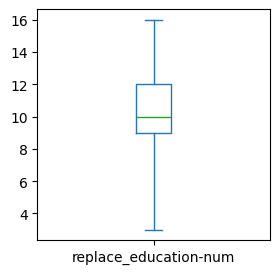

In [48]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['replace_education-num'].plot.box(whis=2)

### marital-status

In [49]:
df_clean['marital-status'].unique()

array(['Never-married', 'Married-civ-spouse', 'Divorced',
       'Married-spouse-absent', 'Separated', 'Married-AF-spouse',
       'Widowed'], dtype=object)

In [50]:
df_clean['marital-status'].value_counts()

,count
marital-status,
Married-civ-spouse,22379
Never-married,16117
Divorced,6633
Separated,1530
Widowed,1518
Married-spouse-absent,628
Married-AF-spouse,37


<Axes: xlabel='marital-status'>

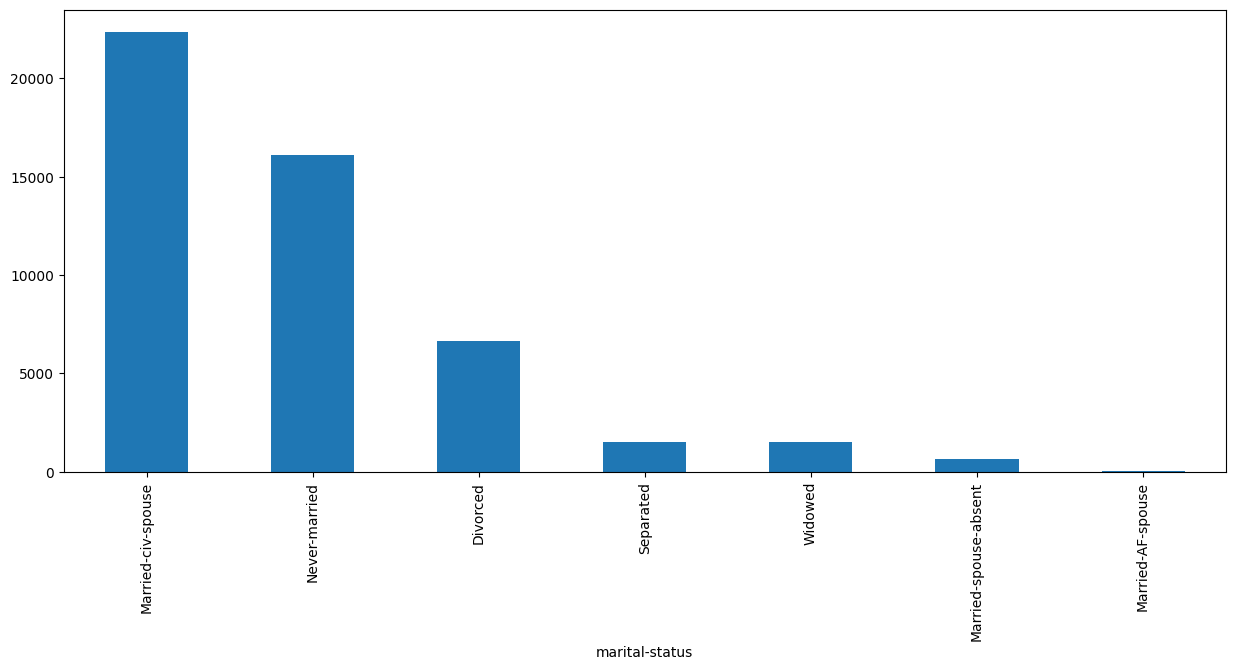

In [51]:
df_clean['marital-status'].value_counts().plot(kind='bar', figsize=(15, 6))

### occupation

In [52]:
df_clean['occupation'].unique()

array(['Adm-clerical', 'Exec-managerial', 'Handlers-cleaners',
       'Prof-specialty', 'Other-service', 'Sales', 'Craft-repair',
       'Transport-moving', 'Farming-fishing', 'Machine-op-inspct',
       'Tech-support', nan, 'Protective-serv', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [53]:
df_clean['occupation'].value_counts()

,count
occupation,
Prof-specialty,6172
Craft-repair,6112
Exec-managerial,6086
Adm-clerical,5611
Sales,5504
Other-service,4923
Machine-op-inspct,3022
Transport-moving,2355
Handlers-cleaners,2072


<Axes: xlabel='occupation'>

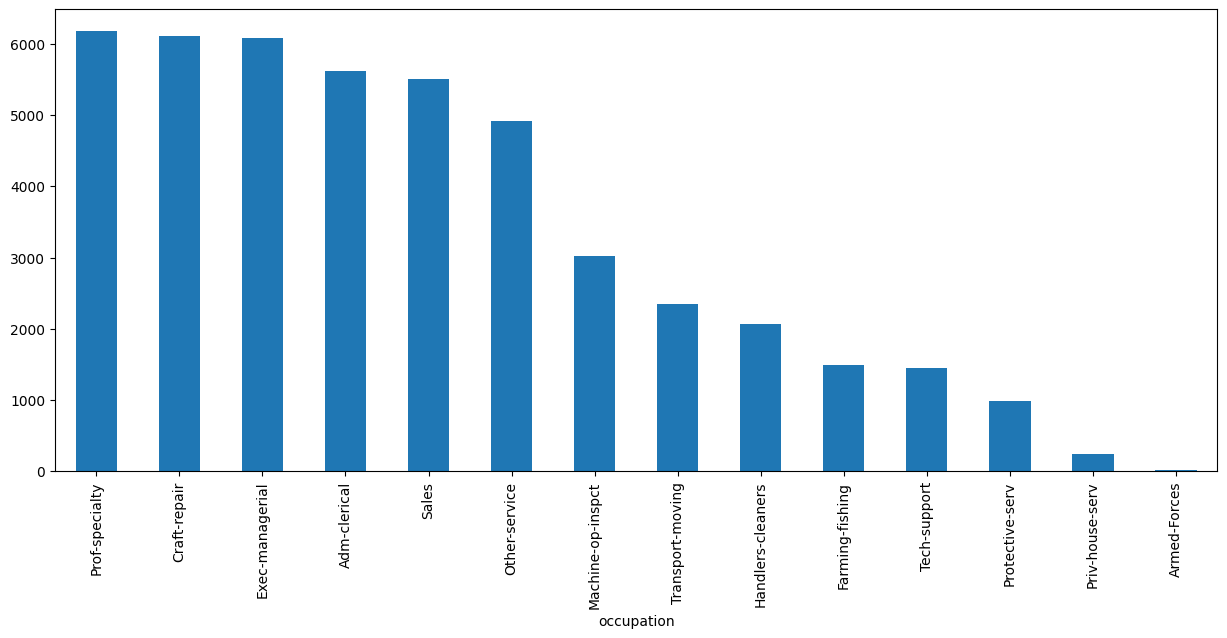

In [54]:
df_clean['occupation'].value_counts().plot(kind='bar', figsize=(15, 6))

### relationship

In [55]:
df_clean['relationship'].unique()

array(['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried',
       'Other-relative'], dtype=object)

In [56]:
df_clean['relationship'].value_counts()

,count
relationship,
Husband,19716
Not-in-family,12583
Own-child,7581
Unmarried,5125
Wife,2331
Other-relative,1506


<Axes: xlabel='relationship'>

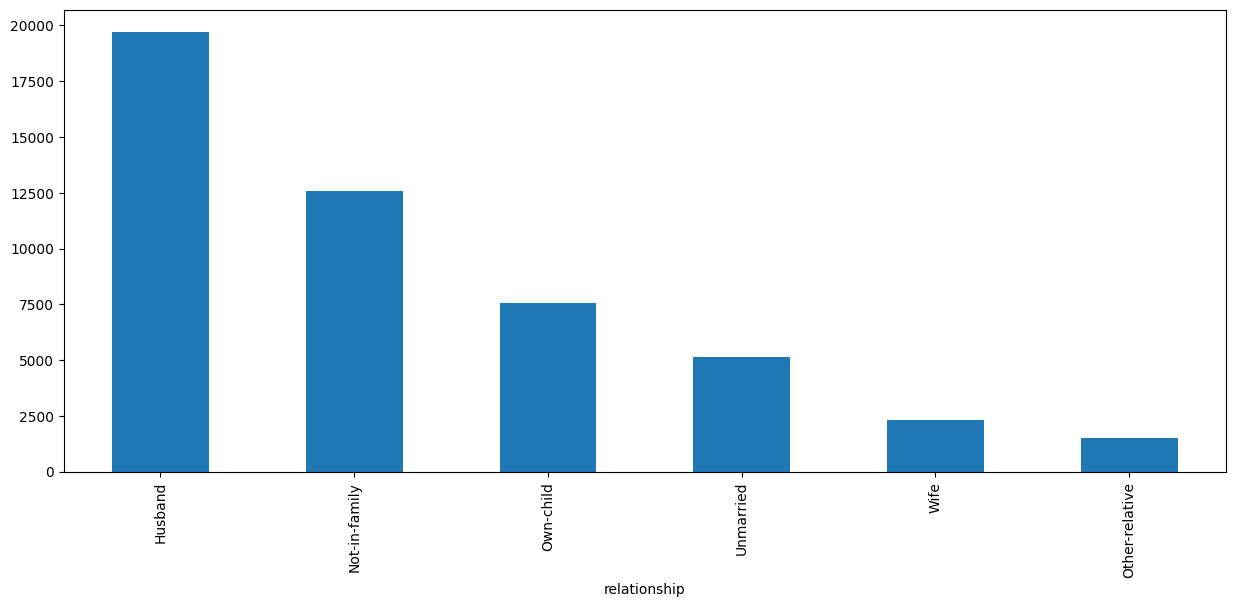

In [57]:
df_clean['relationship'].value_counts().plot(kind='bar', figsize=(15, 6))

### race

In [58]:
df_clean['race'].unique()

array(['White', 'Black', 'Asian-Pac-Islander', 'Amer-Indian-Eskimo',
       'Other'], dtype=object)

In [59]:
df_clean['race'].value_counts()

,count
race,
White,41762
Black,4685
Asian-Pac-Islander,1519
Amer-Indian-Eskimo,470
Other,406


<Axes: xlabel='race'>

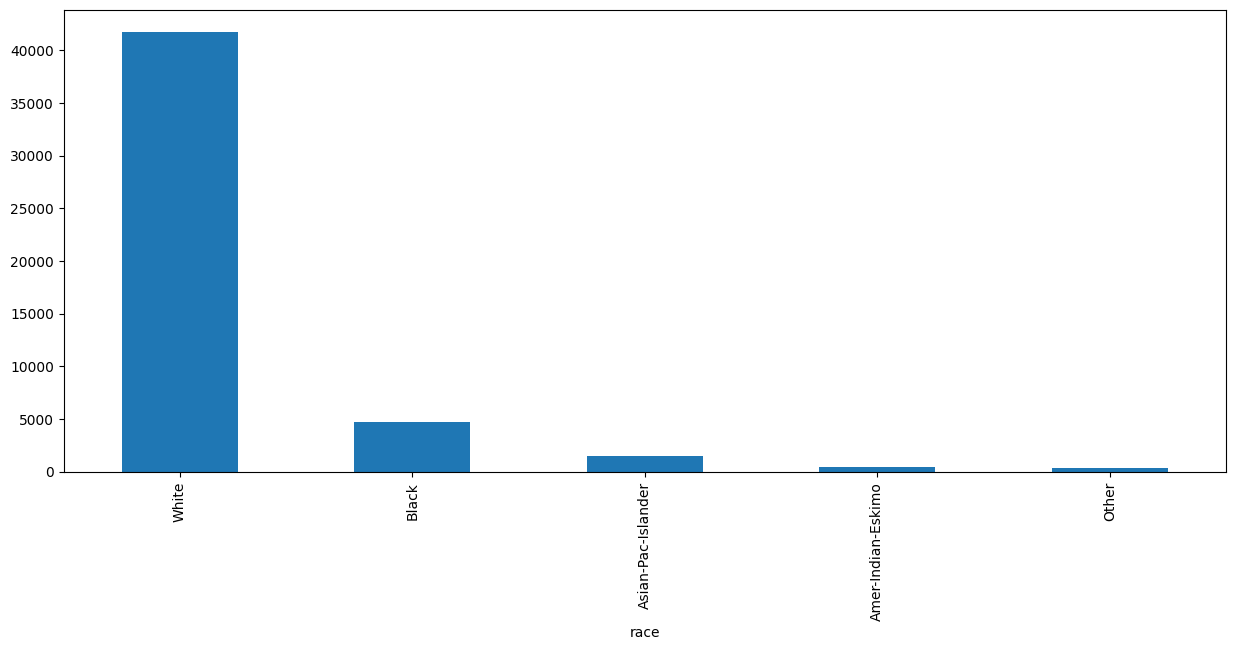

In [60]:
df_clean['race'].value_counts().plot(kind='bar', figsize=(15, 6))

### sex

In [61]:
df_clean['sex'].unique()

array(['Male', 'Female'], dtype=object)

In [62]:
df_clean['sex'].value_counts()

,count
sex,
Male,32650
Female,16192


<Axes: xlabel='sex'>

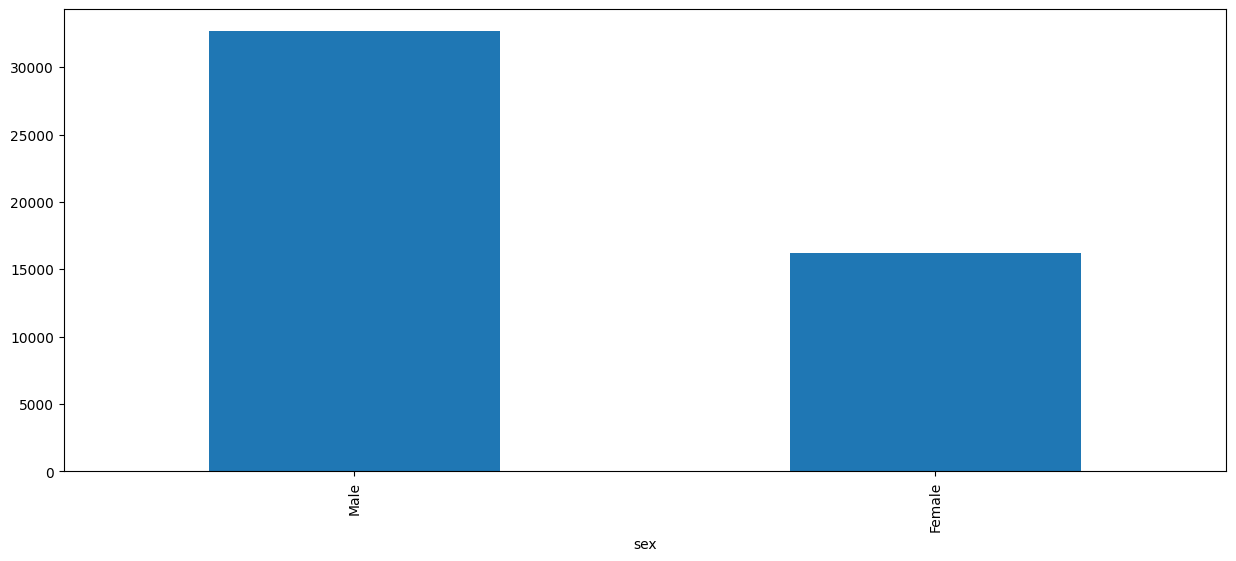

In [63]:
df_clean['sex'].value_counts().plot(kind='bar', figsize=(15, 6))

### capital-gain

<Axes: >

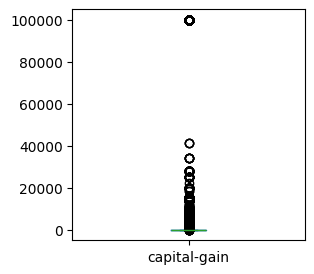

In [64]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['capital-gain'].plot.box(whis=2)

In [65]:
df_clean['capital-gain'].describe()

,capital-gain
count,48842.000000
mean,1079.067626
std,7452.019058
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,99999.000000


<Axes: ylabel='Density'>

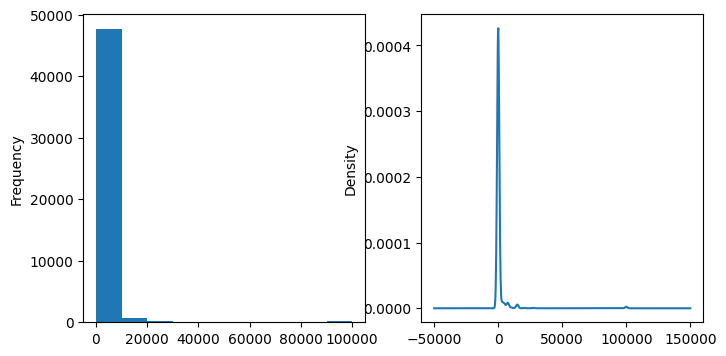

In [66]:
fig, ax = plt.subplots(1,2, figsize=(8,4))
df_clean['capital-gain'].plot.hist(bins=10, ax=ax[0])
df_clean['capital-gain'].plot.density(ax=ax[1])

In [67]:
def check_outliers(x, factor):
  q25 = x.quantile(.25)
  q75 = x.quantile(.75)
  IQR = q75-q25
  l = q25 - IQR*factor
  u = q75 + IQR*factor
  return l, u

In [68]:
lower, upper = check_outliers(df_clean['capital-gain'],2)
print(f'lower = {lower}, upper={upper}')

lower = 0.0, upper=0.0


In [69]:
mask_lower = df_clean['capital-gain']< lower
mask_lower.sum()

np.int64(0)

In [70]:
mask_upper = df_clean['capital-gain']>upper
mask_upper.sum()

np.int64(4035)

In [71]:
df_clean[mask_upper]

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income,replace_age,replace_education-num
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,39.0,13.0
8,31,Private,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K,31.0,14.0
9,42,Private,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K,42.0,13.0
59,30,Private,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,5013,0,40,United-States,<=50K,30.0,9.0
60,30,Private,Bachelors,13,Married-civ-spouse,Sales,Husband,White,Male,2407,0,40,United-States,<=50K,30.0,13.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48805,32,Private,Assoc-voc,11,Married-civ-spouse,Sales,Husband,White,Male,5178,0,60,United-States,>50K.,32.0,11.0
48812,81,NaN,Assoc-voc,11,Married-civ-spouse,NaN,Husband,White,Male,2936,0,20,United-States,<=50K.,81.0,11.0
48813,60,Private,Assoc-voc,11,Married-civ-spouse,Prof-specialty,Husband,White,Male,7688,0,40,United-States,>50K.,60.0,11.0
48822,40,Private,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,15024,0,55,United-States,>50K.,40.0,15.0


*Replacing outliers:*

In [72]:
# Replacing outliers becuase high gains are valid income indicators

In [73]:
df_clean['replace_capital-gain'] = df_clean['capital-gain'].map(lambda x: upper if x>upper else lower if x<lower else x)

<Axes: >

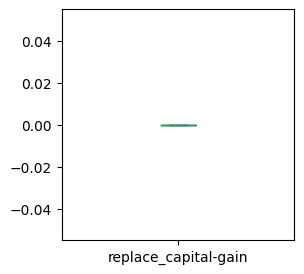

In [74]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['replace_capital-gain'].plot.box(whis=2)

### capital-loss

<Axes: >

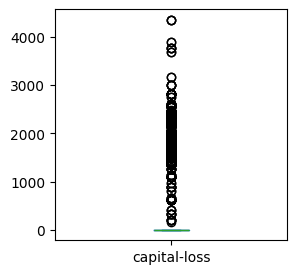

In [75]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['capital-loss'].plot.box(whis=2)

In [76]:
df_clean['capital-loss'].describe()

,capital-loss
count,48842.000000
mean,87.502314
std,403.004552
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,4356.000000


<Axes: ylabel='Density'>

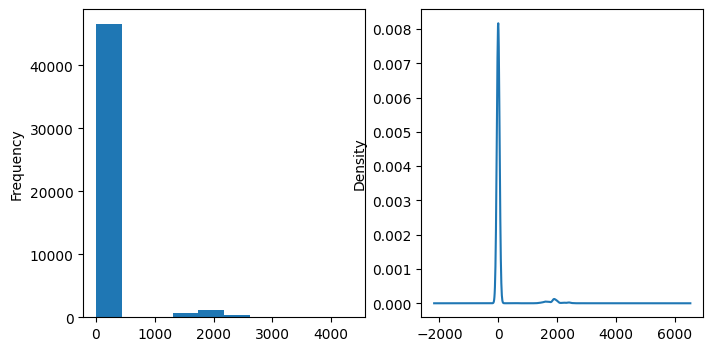

In [77]:
fig, ax = plt.subplots(1,2, figsize=(8,4))
df_clean['capital-loss'].plot.hist(bins=10, ax=ax[0])
df_clean['capital-loss'].plot.density(ax=ax[1])

In [78]:
def check_outliers(x, factor):
  q25 = x.quantile(.25)
  q75 = x.quantile(.75)
  IQR = q75-q25
  l = q25 - IQR*factor
  u = q75 + IQR*factor
  return l, u

In [79]:
lower, upper = check_outliers(df_clean['capital-loss'],2)
print(f'lower = {lower}, upper={upper}')

lower = 0.0, upper=0.0


In [80]:
mask_lower = df_clean['capital-loss']< lower
mask_lower.sum()

np.int64(0)

In [81]:
mask_upper = df_clean['capital-loss']>upper
mask_upper.sum()

np.int64(2282)

In [82]:
df_clean[mask_upper]

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income,replace_age,replace_education-num,replace_capital-gain
23,43,Private,11th,7,Married-civ-spouse,Transport-moving,Husband,White,Male,0,2042,40,United-States,<=50K,43.0,7.0,0.0
32,45,Private,Bachelors,13,Divorced,Exec-managerial,Own-child,White,Male,0,1408,40,United-States,<=50K,45.0,13.0,0.0
52,47,Private,Prof-school,15,Married-civ-spouse,Prof-specialty,Wife,White,Female,0,1902,60,Honduras,>50K,47.0,15.0,0.0
93,30,Private,HS-grad,9,Married-civ-spouse,Sales,Wife,Asian-Pac-Islander,Female,0,1573,35,NaN,<=50K,30.0,9.0,0.0
96,48,Self-emp-not-inc,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,1902,60,United-States,>50K,48.0,16.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48783,19,Private,HS-grad,9,Never-married,Other-service,Own-child,White,Female,0,1602,20,United-States,<=50K.,19.0,9.0,0.0
48794,29,Local-gov,HS-grad,9,Married-civ-spouse,Protective-serv,Husband,Black,Male,0,2057,40,United-States,<=50K.,29.0,9.0,0.0
48802,51,Private,Bachelors,13,Divorced,Tech-support,Not-in-family,White,Male,0,1590,40,United-States,<=50K.,51.0,13.0,0.0
48814,39,Private,Bachelors,13,Never-married,Tech-support,Not-in-family,White,Female,0,1669,40,United-States,<=50K.,39.0,13.0,0.0


*Replacing outliers:*

In [83]:
# Replacing outliers becuase high losses are valid income indicators

In [84]:
df_clean['replace_capital-loss'] = df_clean['capital-loss'].map(lambda x: upper if x>upper else lower if x<lower else x)

<Axes: >

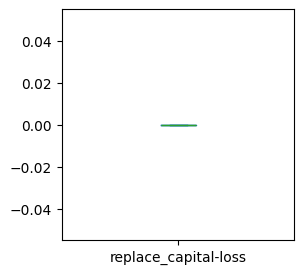

In [85]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['replace_capital-loss'].plot.box(whis=2)

### hours-per-week

<Axes: >

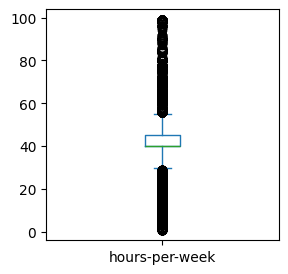

In [86]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['hours-per-week'].plot.box(whis=2)

In [87]:
df_clean['hours-per-week'].describe()

,hours-per-week
count,48842.000000
mean,40.422382
std,12.391444
min,1.000000
25%,40.000000
50%,40.000000
75%,45.000000
max,99.000000


<Axes: ylabel='Density'>

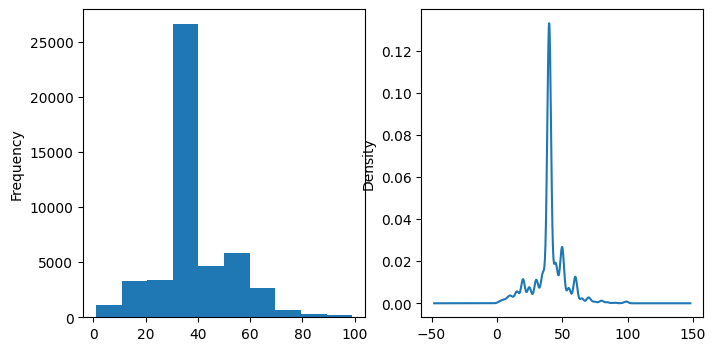

In [88]:
fig, ax = plt.subplots(1,2, figsize=(8,4))
df_clean['hours-per-week'].plot.hist(bins=10, ax=ax[0])
df_clean['hours-per-week'].plot.density(ax=ax[1])

In [89]:
def check_outliers(x, factor):
  q25 = x.quantile(.25)
  q75 = x.quantile(.75)
  IQR = q75-q25
  l = q25 - IQR*factor
  u = q75 + IQR*factor
  return l, u

In [90]:
lower, upper = check_outliers(df_clean['hours-per-week'],2)
print(f'lower = {lower}, upper={upper}')

lower = 30.0, upper=55.0


In [91]:
mask_lower = df_clean['hours-per-week']< lower
mask_lower.sum()

np.int64(6151)

In [92]:
mask_upper = df_clean['hours-per-week']>upper
mask_upper.sum()

np.int64(4058)

In [93]:
df_clean[mask_lower]

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income,replace_age,replace_education-num,replace_capital-gain,replace_capital-loss
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,50.0,13.0,0.0,0.0
6,49,Private,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K,49.0,5.0,0.0,0.0
21,54,Private,HS-grad,9,Separated,Other-service,Unmarried,Black,Female,0,0,20,United-States,<=50K,54.0,9.0,0.0,0.0
34,22,State-gov,Some-college,10,Married-civ-spouse,Other-service,Husband,Black,Male,0,0,15,United-States,<=50K,22.0,10.0,0.0,0.0
37,19,Private,HS-grad,9,Married-AF-spouse,Adm-clerical,Wife,White,Female,0,0,25,United-States,<=50K,19.0,9.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48787,66,Self-emp-not-inc,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,20,United-States,<=50K.,66.0,15.0,0.0,0.0
48800,73,NaN,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,0,25,Canada,<=50K.,73.0,9.0,0.0,0.0
48807,19,Private,9th,5,Never-married,Craft-repair,Own-child,White,Male,0,0,20,United-States,<=50K.,19.0,5.0,0.0,0.0
48812,81,NaN,Assoc-voc,11,Married-civ-spouse,NaN,Husband,White,Male,2936,0,20,United-States,<=50K.,81.0,11.0,0.0,0.0


In [94]:
df_clean[mask_upper]

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income,replace_age,replace_education-num,replace_capital-gain,replace_capital-loss
10,37,Private,Some-college,10,Married-civ-spouse,Exec-managerial,Husband,Black,Male,0,0,80,United-States,>50K,37.0,10.0,0.0,0.0
20,40,Private,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,>50K,40.0,16.0,0.0,0.0
27,54,NaN,Some-college,10,Married-civ-spouse,NaN,Husband,Asian-Pac-Islander,Male,0,0,60,South,>50K,54.0,10.0,0.0,0.0
28,39,Private,HS-grad,9,Divorced,Exec-managerial,Not-in-family,White,Male,0,0,80,United-States,<=50K,39.0,9.0,0.0,0.0
52,47,Private,Prof-school,15,Married-civ-spouse,Prof-specialty,Wife,White,Female,0,1902,60,Honduras,>50K,47.0,15.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48782,60,Private,7th-8th,4,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,60,United-States,<=50K.,60.0,4.0,0.0,0.0
48798,30,Private,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,80,United-States,>50K.,30.0,15.0,0.0,0.0
48801,57,Private,Some-college,10,Married-civ-spouse,Prof-specialty,Husband,White,Male,7688,0,60,United-States,>50K.,57.0,10.0,0.0,0.0
48805,32,Private,Assoc-voc,11,Married-civ-spouse,Sales,Husband,White,Male,5178,0,60,United-States,>50K.,32.0,11.0,0.0,0.0


*Replacing outliers:*

In [95]:
# Replacing outliers because extremely high or low hours a week are rare but not invalid

In [96]:
df_clean['replace_hours-per-week'] = df_clean['hours-per-week'].map(lambda x: upper if x>upper else lower if x<lower else x)

<Axes: >

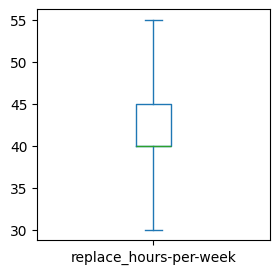

In [97]:
fig, ax = plt.subplots(1, figsize=(3,3))
df_clean['replace_hours-per-week'].plot.box(whis=2)

### native-country

In [98]:
df_clean['native-country'].unique()

array(['United-States', 'Cuba', 'Jamaica', 'India', nan, 'Mexico',
       'South', 'Puerto-Rico', 'Honduras', 'England', 'Canada', 'Germany',
       'Iran', 'Philippines', 'Italy', 'Poland', 'Columbia', 'Cambodia',
       'Thailand', 'Ecuador', 'Laos', 'Taiwan', 'Haiti', 'Portugal',
       'Dominican-Republic', 'El-Salvador', 'France', 'Guatemala',
       'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-US(Guam-USVI-etc)', 'Scotland', 'Trinadad&Tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Hong', 'Ireland', 'Hungary',
       'Holand-Netherlands'], dtype=object)

In [99]:
df_clean['native-country'].value_counts()

,count
native-country,
United-States,43832
Mexico,951
Philippines,295
Germany,206
Puerto-Rico,184
Canada,182
El-Salvador,155
India,151
Cuba,138


<Axes: xlabel='native-country'>

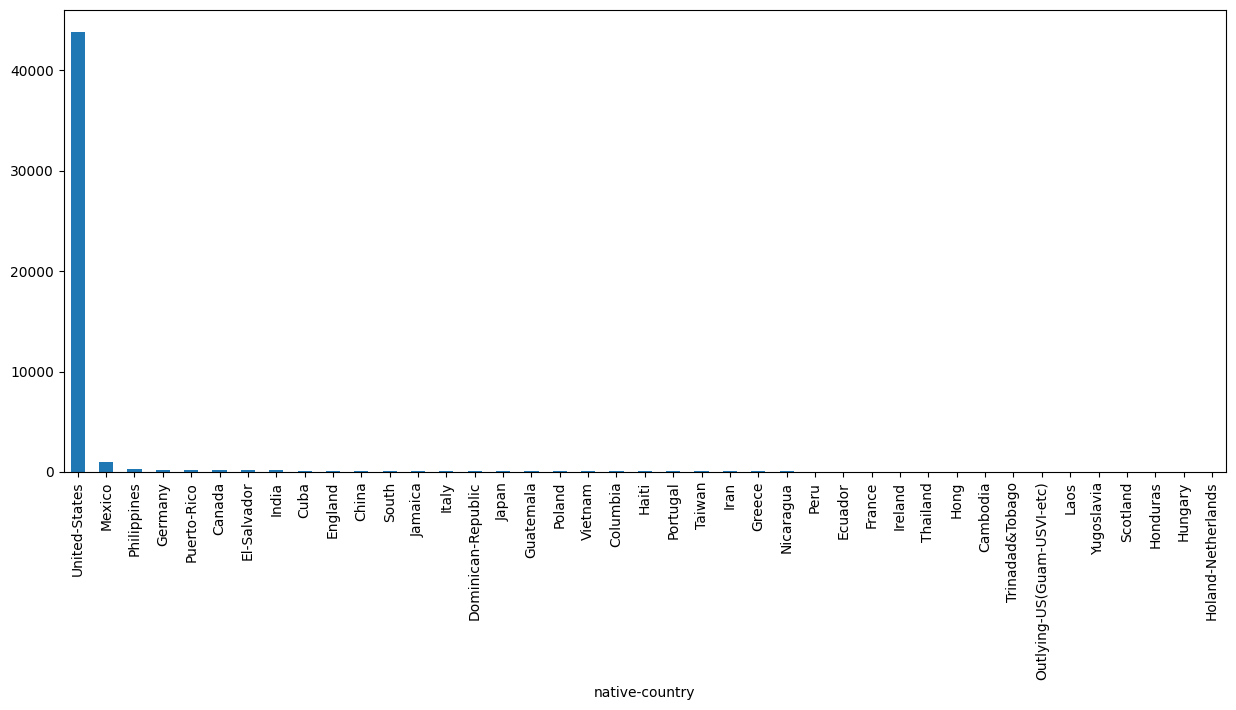

In [100]:
df_clean['native-country'].value_counts().plot(kind='bar', figsize=(15, 6))

native-country has over 40 unique categories, but the Adult dataset is very imbalanced:

* “United-States” appears over 80% of the time.
* Most other countries appear fewer than 100–500 times.

To decide which categories to group into "Other", I chose to group the values that are less than 1% of the Adult dataset size.

In [101]:
other_threshold = 48842 * 0.01
other_threshold

488.42

In [102]:
rare_countries = df_clean['native-country'].value_counts()[lambda x: x < other_threshold].index
df_clean['native-country'] = df_clean['native-country'].replace(rare_countries, "Other")

<Axes: xlabel='native-country'>

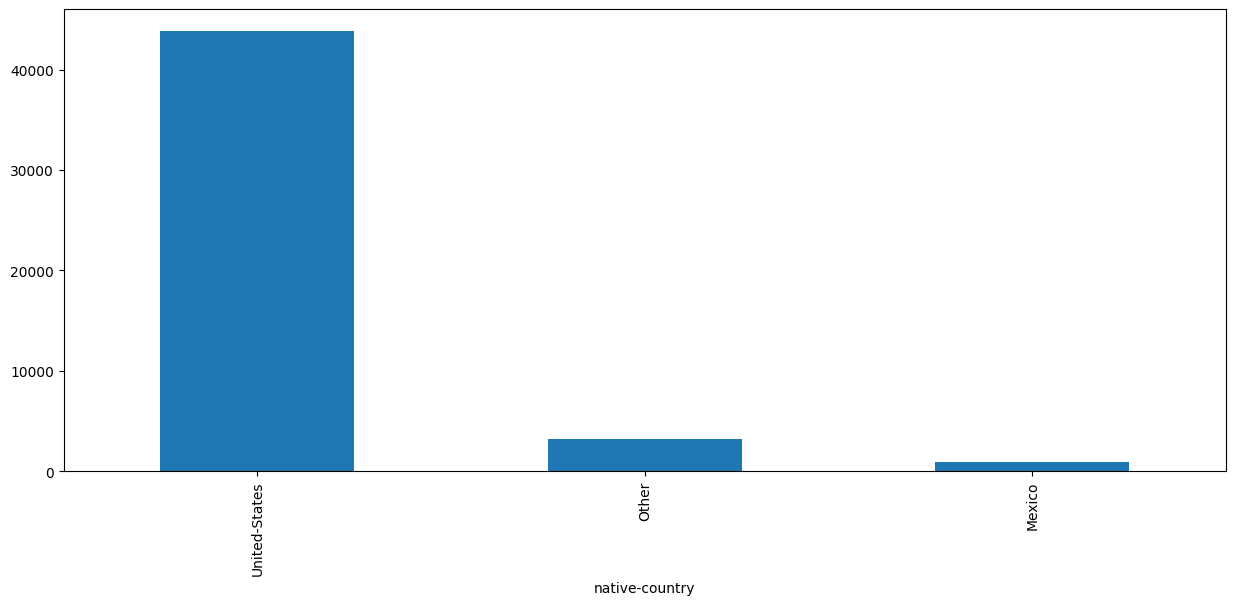

In [103]:
df_clean['native-country'].value_counts().plot(kind='bar', figsize=(15, 6))

### income

In [104]:
df_clean['Income'] = df_clean['Income'].str.strip().str.replace('.', '', regex=False)

In [105]:
df_clean['Income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [106]:
df_clean['Income'].value_counts()

,count
Income,
<=50K,37155
>50K,11687


<Axes: xlabel='Income'>

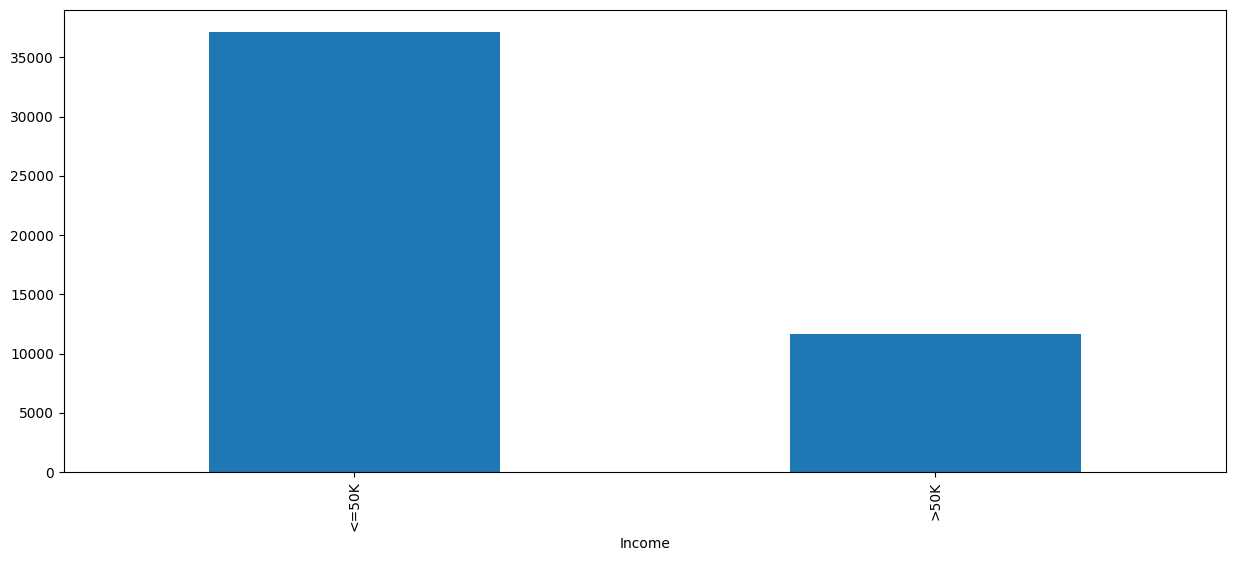

In [107]:
df_clean['Income'].value_counts().plot(kind='bar', figsize=(15, 6))

3. continued...
    * c. Perform feature selection (*)

In [108]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     48842 non-null  int64  
 1   workclass               46043 non-null  object 
 2   education               48842 non-null  object 
 3   education-num           48842 non-null  int64  
 4   marital-status          48842 non-null  object 
 5   occupation              46033 non-null  object 
 6   relationship            48842 non-null  object 
 7   race                    48842 non-null  object 
 8   sex                     48842 non-null  object 
 9   capital-gain            48842 non-null  int64  
 10  capital-loss            48842 non-null  int64  
 11  hours-per-week          48842 non-null  int64  
 12  native-country          47985 non-null  object 
 13  Income                  48842 non-null  object 
 14  replace_age             48842 non-null

In [109]:
# Drop education because it represents the same thing as education-num

In [110]:
df_clean = df_clean.drop(columns=['education'])

In [111]:
# Drop original columns after creating replace_columns

In [112]:
df_clean = df_clean.drop(columns=['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week'])

In [113]:
# df_fs is the working dataframe for feature selection

In [114]:
df_fs = df_clean.copy()
df_fs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   workclass               46043 non-null  object 
 1   marital-status          48842 non-null  object 
 2   occupation              46033 non-null  object 
 3   relationship            48842 non-null  object 
 4   race                    48842 non-null  object 
 5   sex                     48842 non-null  object 
 6   native-country          47985 non-null  object 
 7   Income                  48842 non-null  object 
 8   replace_age             48842 non-null  float64
 9   replace_education-num   48842 non-null  float64
 10  replace_capital-gain    48842 non-null  float64
 11  replace_capital-loss    48842 non-null  float64
 12  replace_hours-per-week  48842 non-null  float64
dtypes: float64(5), object(8)
memory usage: 4.8+ MB


In [115]:
y_fs = df_fs['Income'].str.strip().str.replace('.', '', regex=False).map({'<=50K': 0, '>50K': 1})
X_fs = df_fs.drop(columns=['Income'])

In [116]:
X_fs_encoded = pd.get_dummies(X_fs, drop_first=True)
X_fs_encoded.shape

(48842, 43)

In [117]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif

# choose how many best features to keep
k = 20 if X_fs_encoded.shape[1] > 20 else 'all'

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=k
)

X_fs_selected = selector.fit_transform(X_fs_encoded, y_fs)

In [118]:
mask = selector.get_support()
selected_feature_names = X_fs_encoded.columns[mask]
selected_feature_names

Index(['replace_age', 'replace_education-num', 'replace_hours-per-week',
       'workclass_Private', 'workclass_Self-emp-inc',
       'marital-status_Married-civ-spouse', 'marital-status_Never-married',
       'occupation_Exec-managerial', 'occupation_Handlers-cleaners',
       'occupation_Other-service', 'occupation_Prof-specialty',
       'occupation_Transport-moving', 'relationship_Not-in-family',
       'relationship_Other-relative', 'relationship_Own-child',
       'relationship_Unmarried', 'relationship_Wife', 'race_White', 'sex_Male',
       'native-country_United-States'],
      dtype='object')

3. continued...
    * d. Perform feature engineering, such as discretize continuous features,
decompose/aggregate features (*)

In [119]:
# Binning age

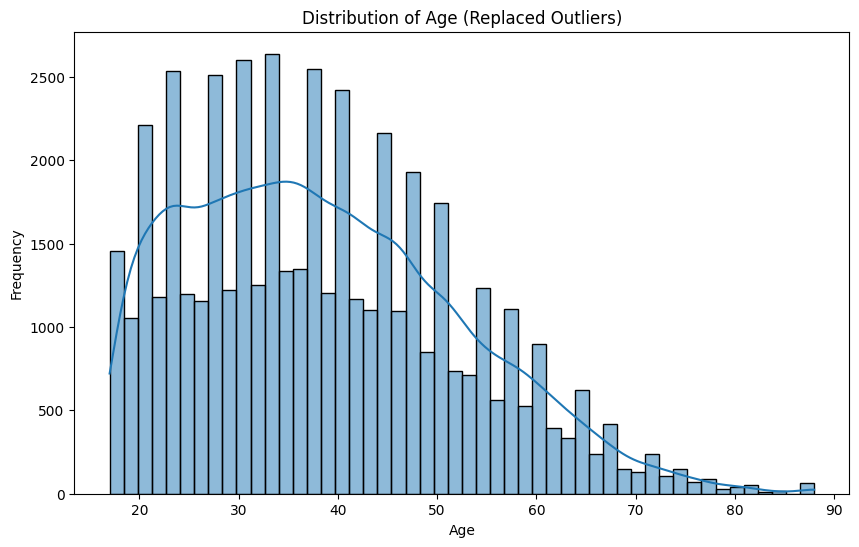

In [120]:
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['replace_age'], bins=50, kde=True)
plt.title('Distribution of Age (Replaced Outliers)')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

In [121]:
bins = [0, 25, 35, 50, 100]
labels = ["<25", "25-35", "35-50", "50+"]
df_clean["age_group"] = pd.cut(df_clean["replace_age"], bins=bins, labels=labels)

In [122]:
# Binning hours-per-week

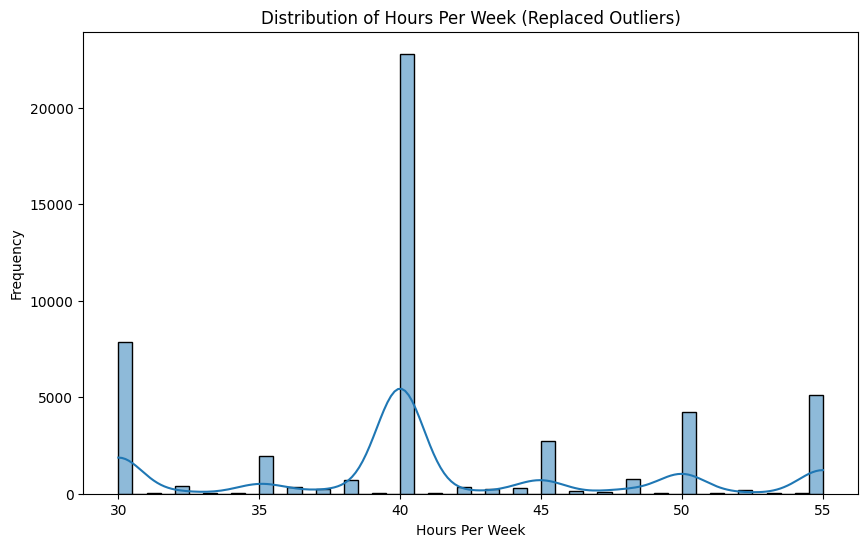

In [123]:
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['replace_hours-per-week'], bins=50, kde=True)
plt.title('Distribution of Hours Per Week (Replaced Outliers)')
plt.xlabel('Hours Per Week')
plt.ylabel('Frequency')
plt.show()

In [124]:
df_clean["works_long_hours"] = (df_clean["replace_hours-per-week"] >= 40).astype(int)

In [125]:
# Binning capital-gain

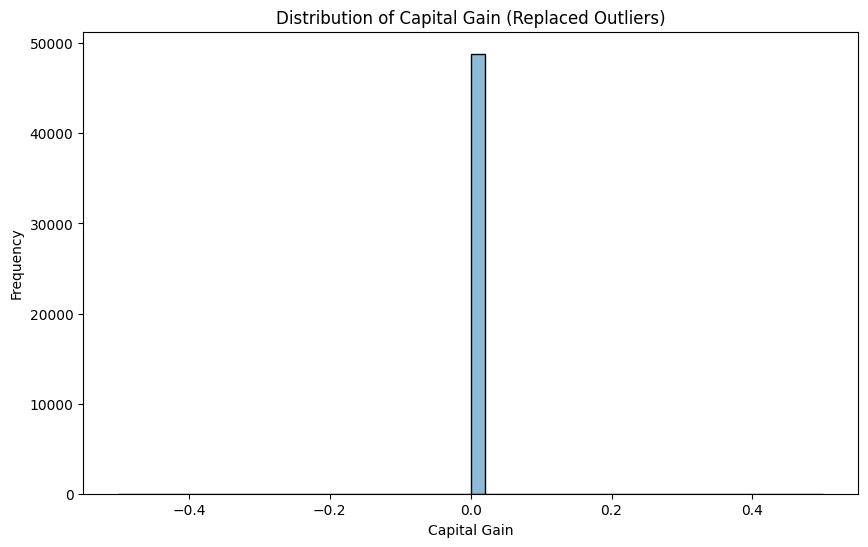

In [126]:
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['replace_capital-gain'], bins=50, kde=True)
plt.title('Distribution of Capital Gain (Replaced Outliers)')
plt.xlabel('Capital Gain')
plt.ylabel('Frequency')
plt.show()

In [127]:
df_clean["capital_gain_bin"] = np.where(
    df_clean["replace_capital-gain"] == 0,
    "none",
    "has_gain"
)

In [128]:
# Binning capital-loss

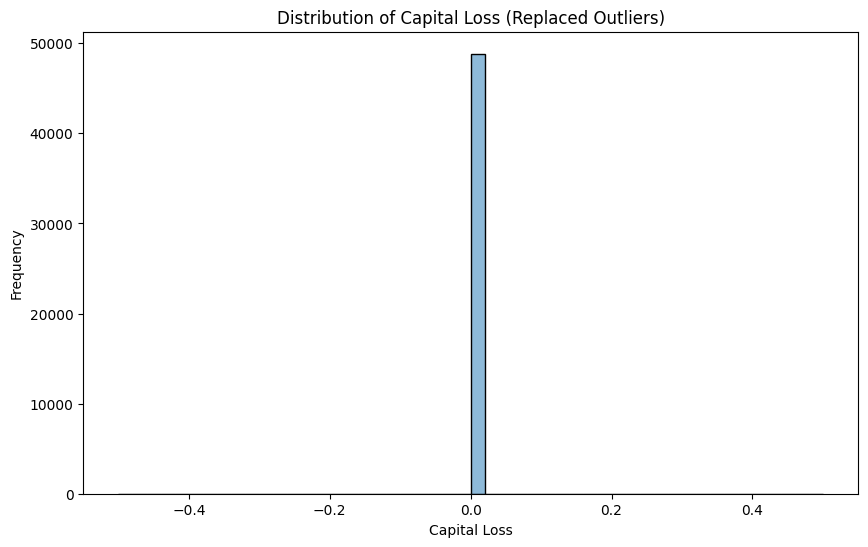

In [129]:
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['replace_capital-loss'], bins=50, kde=True)
plt.title('Distribution of Capital Loss (Replaced Outliers)')
plt.xlabel('Capital Loss')
plt.ylabel('Frequency')
plt.show()

In [130]:
df_clean["capital_loss_bin"] = np.where(
    df_clean["replace_capital-loss"] == 0,
    "none",
    "has_loss"
)

3. continued...
    * e. Feature scaling standardize or normalize features.

In [131]:
from sklearn.preprocessing import StandardScaler

# Identify continuous numeric features
numeric_cols = [
    'replace_age',
    'replace_education-num',
    'replace_hours-per-week',
    'replace_capital-gain',
    'replace_capital-loss'
]

# Build a DataFrame from X_fs_encoded (dummies + engineered features)
X_fs_selected_df = pd.DataFrame(X_fs_encoded, columns=X_fs_encoded.columns)

# Keep only numeric columns that exist in the selected features
selected_numeric = [col for col in numeric_cols if col in X_fs_selected_df.columns]

# Initialize scaler
scaler = StandardScaler()

# Fit and transform ONLY selected numeric features
scaled_numeric = scaler.fit_transform(X_fs_selected_df[selected_numeric])

# Replace numeric columns with scaled versions
X_fs_selected_df[selected_numeric] = scaled_numeric

X_fs_processed = X_fs_selected_df.copy()

print(X_fs_processed.shape)
X_fs_processed.head()

(48842, 43)


,replace_age,replace_education-num,replace_capital-gain,replace_capital-loss,replace_hours-per-week,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,native-country_Other,native-country_United-States
0,0.026179,1.144678,0.0,0.0,-0.144334,False,False,False,False,False,...,False,False,False,False,False,False,True,True,False,True
1,0.828985,1.144678,0.0,0.0,-1.518862,False,False,False,False,True,...,False,False,False,False,False,False,True,True,False,True
2,-0.046803,-0.426896,0.0,0.0,-0.144334,False,False,True,False,False,...,False,False,False,False,False,False,True,True,False,True
3,1.047932,-1.212683,0.0,0.0,-0.144334,False,False,True,False,False,...,False,False,False,False,True,False,False,True,False,True
4,-0.776626,1.144678,0.0,0.0,-0.144334,False,False,True,False,False,...,False,False,True,False,True,False,False,False,True,False


In [132]:
from sklearn.model_selection import train_test_split

# X: your processed features after selection + scaling
X = X_fs_processed

# y: clean binary target
y = (
    df_clean['Income']
    .str.strip()
    .str.replace('.', '', regex=False)
    .map({'<=50K': 0, '>50K': 1})
)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((39073, 43), (9769, 43), (39073,), (9769,))



---



## Step 4

4. Explore many different models and short-list the best ones (spiral approach)
    * a. Train many models from different categories using standard parameters.

In [133]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# ---------------------------------------
# 1. Initialize models with standard parameters
# ---------------------------------------

models = {
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

# ---------------------------------------
# 2. Train and evaluate each model
# ---------------------------------------

results = {}

for name, model in models.items():
    # Train on training set
    model.fit(X_train, y_train)

    # Predict on test set
    y_pred = model.predict(X_test)

    # Compute accuracy
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print(f"\n===== {name} =====")
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred))

# ---------------------------------------
# 3. Summary of accuracies
# ---------------------------------------
print("\n\nModel Accuracy Summary:")
for name, acc in results.items():
    print(f"{name}: {acc:.4f}")



===== KNN =====
Accuracy: 0.8204524516327157
              precision    recall  f1-score   support

           0       0.87      0.90      0.88      7431
           1       0.64      0.57      0.60      2338

    accuracy                           0.82      9769
   macro avg       0.75      0.74      0.74      9769
weighted avg       0.81      0.82      0.82      9769


===== Naive Bayes =====
Accuracy: 0.587777664039308
              precision    recall  f1-score   support

           0       0.95      0.48      0.64      7431
           1       0.36      0.92      0.52      2338

    accuracy                           0.59      9769
   macro avg       0.66      0.70      0.58      9769
weighted avg       0.81      0.59      0.61      9769


===== Decision Tree =====
Accuracy: 0.7890265124373017
              precision    recall  f1-score   support

           0       0.86      0.87      0.86      7431
           1       0.56      0.54      0.55      2338

    accuracy               

4. continued...
    * b. Measure and compare their performance.


===== MODEL PERFORMANCE COMPARISON =====


### KNN ###
Accuracy: 0.8204524516327157
              precision    recall  f1-score   support

           0       0.87      0.90      0.88      7431
           1       0.64      0.57      0.60      2338

    accuracy                           0.82      9769
   macro avg       0.75      0.74      0.74      9769
weighted avg       0.81      0.82      0.82      9769



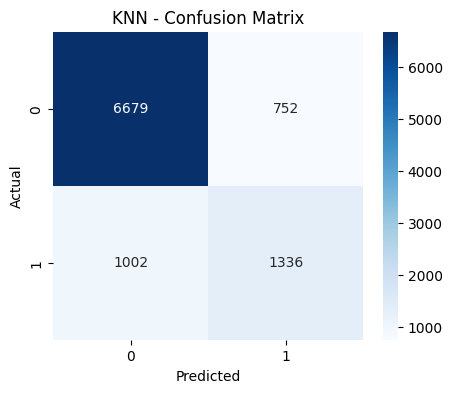



### Naive Bayes ###
Accuracy: 0.587777664039308
              precision    recall  f1-score   support

           0       0.95      0.48      0.64      7431
           1       0.36      0.92      0.52      2338

    accuracy                           0.59      9769
   macro avg       0.66      0.70      0.58      9769
weighted avg       0.81      0.59      0.61      9769



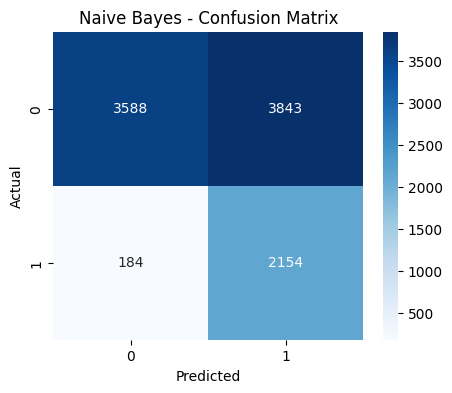



### Decision Tree ###
Accuracy: 0.7890265124373017
              precision    recall  f1-score   support

           0       0.86      0.87      0.86      7431
           1       0.56      0.54      0.55      2338

    accuracy                           0.79      9769
   macro avg       0.71      0.70      0.71      9769
weighted avg       0.79      0.79      0.79      9769



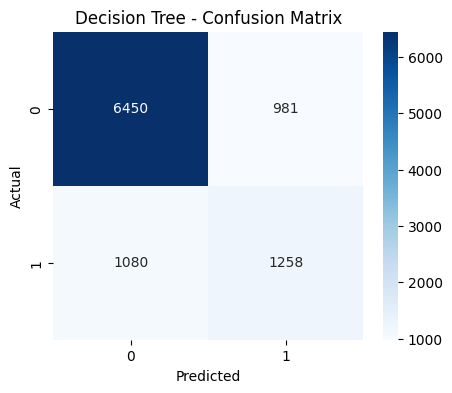


==== Summary Table ====


,Model,Accuracy
0,KNN,0.820452
2,Decision Tree,0.789027
1,Naive Bayes,0.587778


In [134]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Dictionary to store results
performance_summary = []

print("\n===== MODEL PERFORMANCE COMPARISON =====")

for name, model in models.items():
    # Predictions
    y_pred = model.predict(X_test)

    # Accuracy
    acc = accuracy_score(y_test, y_pred)

    # Classification report
    print(f"\n\n### {name} ###")
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred))

    # Add to comparison table
    performance_summary.append({
        "Model": name,
        "Accuracy": acc
    })

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# Create comparison dataframe
performance_df = pd.DataFrame(performance_summary).sort_values(by="Accuracy", ascending=False)

print("\n==== Summary Table ====")
display(performance_df)

4. continued...
    * c. Analyze the most significant variables for each algorithm.

In [135]:
tree_model = models["Decision Tree"]

tree_importances = pd.Series(
    tree_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

tree_top10 = tree_importances.head(10)
tree_top10

,0
marital-status_Married-civ-spouse,0.225927
replace_age,0.225804
replace_education-num,0.175172
replace_hours-per-week,0.105483
workclass_Private,0.021610
occupation_Exec-managerial,0.016095
workclass_Self-emp-not-inc,0.015205
occupation_Craft-repair,0.014236
native-country_United-States,0.013598
race_White,0.013009


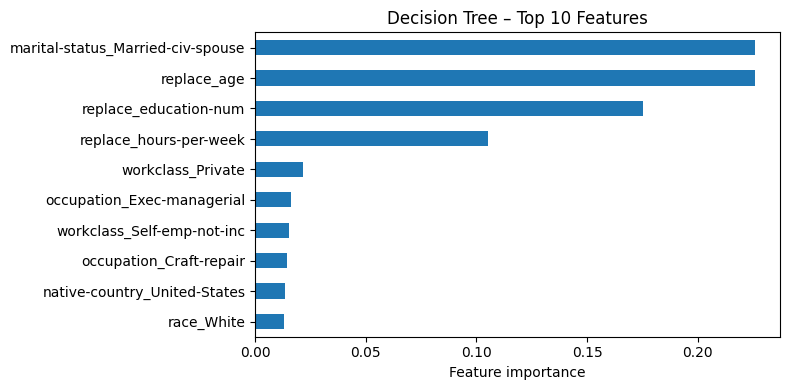

In [136]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
tree_top10[::-1].plot(kind="barh")
plt.title("Decision Tree – Top 10 Features")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [137]:
from sklearn.inspection import permutation_importance

def permutation_top_features(model, X, y, n_repeats=3, n_top=10):
    r = permutation_importance(
        model,
        X,
        y,
        n_repeats=n_repeats,
        random_state=42,
        n_jobs=-1
    )
    importances = pd.Series(r.importances_mean, index=X.columns)
    return importances.sort_values(ascending=False).head(n_top)

In [138]:
# Take a random subset of the test set for importance
X_pi = X_test.sample(n=1500, random_state=42)
y_pi = y_test.loc[X_pi.index]

In [139]:
# Top 10 for KNN
knn_model = models["KNN"]
knn_top10 = permutation_top_features(knn_model, X_pi, y_pi, n_repeats=3, n_top=10)
knn_top10

,0
replace_education-num,0.031778
replace_hours-per-week,0.015111
replace_age,0.010889
occupation_Exec-managerial,0.009556
occupation_Craft-repair,0.008889
marital-status_Married-civ-spouse,0.007778
workclass_Self-emp-not-inc,0.006667
relationship_Not-in-family,0.004889
workclass_Private,0.004444
occupation_Transport-moving,0.003333


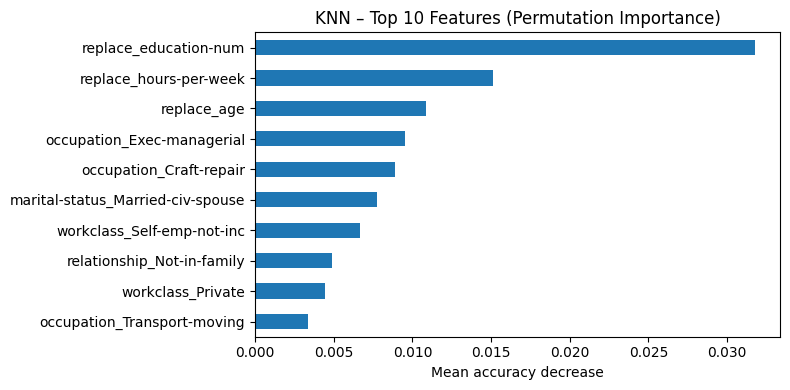

In [140]:
plt.figure(figsize=(8,4))
knn_top10[::-1].plot(kind="barh")
plt.title("KNN – Top 10 Features (Permutation Importance)")
plt.xlabel("Mean accuracy decrease")
plt.tight_layout()
plt.show()

In [141]:
# Top 10 for Naive Bayes
nb_model = models["Naive Bayes"]
nb_top10 = permutation_top_features(nb_model, X_test, y_test)
nb_top10

,0
relationship_Own-child,0.059099
occupation_Other-service,0.013580
relationship_Other-relative,0.008121
marital-status_Widowed,0.008019
relationship_Unmarried,0.007814
occupation_Handlers-cleaners,0.006244
marital-status_Separated,0.004470
marital-status_Married-spouse-absent,0.003003
workclass_Self-emp-inc,0.001945
marital-status_Married-civ-spouse,0.001604


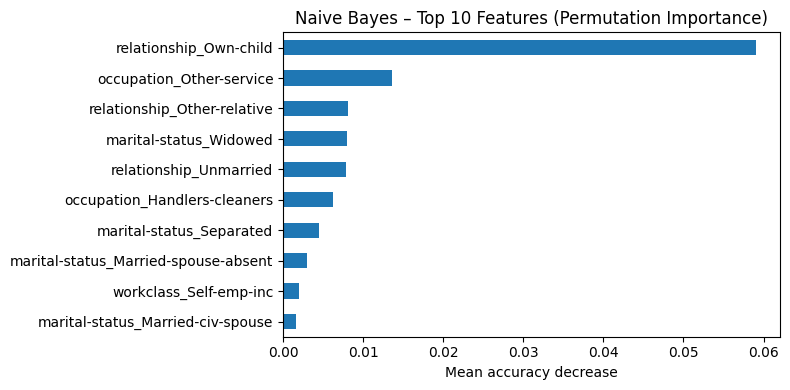

In [142]:
plt.figure(figsize=(8,4))
nb_top10[::-1].plot(kind="barh")
plt.title("Naive Bayes – Top 10 Features (Permutation Importance)")
plt.xlabel("Mean accuracy decrease")
plt.tight_layout()
plt.show()

4. continued...
    * d. Have another round of feature selection and engineering.

In [143]:
# 1) Collect top features from each model
important_feats = set(tree_top10.index) \
    | set(knn_top10.index) \
    | set(nb_top10.index)

len(important_feats), important_feats

(21,
 {'marital-status_Married-civ-spouse',
  'marital-status_Married-spouse-absent',
  'marital-status_Separated',
  'marital-status_Widowed',
  'native-country_United-States',
  'occupation_Craft-repair',
  'occupation_Exec-managerial',
  'occupation_Handlers-cleaners',
  'occupation_Other-service',
  'occupation_Transport-moving',
  'race_White',
  'relationship_Not-in-family',
  'relationship_Other-relative',
  'relationship_Own-child',
  'relationship_Unmarried',
  'replace_age',
  'replace_education-num',
  'replace_hours-per-week',
  'workclass_Private',
  'workclass_Self-emp-inc',
  'workclass_Self-emp-not-inc'})

In [144]:
# 2) Build reduced train/test sets using only these important features
X_train_reduced = X_train[list(important_feats)]
X_test_reduced  = X_test[list(important_feats)]

X_train_reduced.shape, X_test_reduced.shape

((39073, 21), (9769, 21))

In [145]:
# 3) Retrain the same three models on the reduced feature set
from sklearn.metrics import accuracy_score

reduced_results = {}

for name, base_model in models.items():
    # clone the model type so we don't overwrite the originals
    model_cls = base_model.__class__
    if name == "Decision Tree":
        model = model_cls(random_state=42)
    else:
        model = model_cls()

    model.fit(X_train_reduced, y_train)
    y_pred = model.predict(X_test_reduced)
    acc = accuracy_score(y_test, y_pred)
    reduced_results[name] = acc

reduced_results

{'KNN': 0.8190193469137066,
 'Naive Bayes': 0.6853311495547139,
 'Decision Tree': 0.7909714402702426}

4. continued...
    * e. Have one or more iterations of the above four previous steps.

In [146]:
# 1) Tune KNN: try different k values
k_values = [3, 5, 7, 9, 11]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_reduced, y_train)
    y_pred = knn.predict(X_test_reduced)
    acc = accuracy_score(y_test, y_pred)
    knn_results.append({"k": k, "accuracy": acc})

knn_results_df = pd.DataFrame(knn_results)
knn_results_df

,k,accuracy
0,3,0.810011
1,5,0.819019
2,7,0.825161
3,9,0.827720
4,11,0.828539


In [147]:
# 2) Tune Decision Tree: try different tree depths
depth_values = [3, 5, 7, 9, None]  # None = no limit
tree_results = []

for d in depth_values:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train_reduced, y_train)
    y_pred = tree.predict(X_test_reduced)
    acc = accuracy_score(y_test, y_pred)
    tree_results.append({"max_depth": d, "accuracy": acc})

tree_results_df = pd.DataFrame(tree_results)
tree_results_df

,max_depth,accuracy
0,3.0,0.821067
1,5.0,0.823933
2,7.0,0.832020
3,9.0,0.833657
4,NaN,0.790971


In [148]:
# 3) Pick the best tuned models (just as variables you might use later)
best_k = knn_results_df.loc[knn_results_df['accuracy'].idxmax(), 'k']
best_depth = tree_results_df.loc[tree_results_df['accuracy'].idxmax(), 'max_depth']

best_knn = KNeighborsClassifier(n_neighbors=int(best_k))
best_knn.fit(X_train_reduced, y_train)

best_tree = DecisionTreeClassifier(max_depth=None if pd.isna(best_depth) else int(best_depth),
                                   random_state=42)
best_tree.fit(X_train_reduced, y_train)

best_k, best_depth

(np.int64(11), np.float64(9.0))

4. continued...
    * f. Finally, short-list the top several promising models, preferring models that make different types of errors.


===== KNN (tuned) =====
Accuracy: 0.8285392568328386
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      7431
           1       0.66      0.57      0.62      2338

    accuracy                           0.83      9769
   macro avg       0.77      0.74      0.75      9769
weighted avg       0.82      0.83      0.82      9769



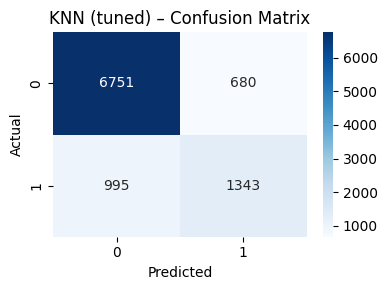


===== Decision Tree (tuned) =====
Accuracy: 0.8336574879721568
              precision    recall  f1-score   support

           0       0.88      0.91      0.89      7431
           1       0.67      0.59      0.63      2338

    accuracy                           0.83      9769
   macro avg       0.77      0.75      0.76      9769
weighted avg       0.83      0.83      0.83      9769



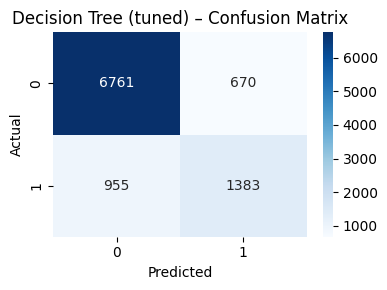


===== Naive Bayes =====
Accuracy: 0.6853311495547139
              precision    recall  f1-score   support

           0       0.95      0.62      0.75      7431
           1       0.43      0.89      0.58      2338

    accuracy                           0.69      9769
   macro avg       0.69      0.76      0.66      9769
weighted avg       0.82      0.69      0.71      9769



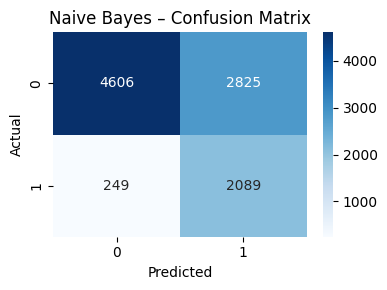

,Model,Accuracy
1,Decision Tree (tuned),0.833657
0,KNN (tuned),0.828539
2,Naive Bayes,0.685331


In [149]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1) Re-fit Naive Bayes on the reduced feature set
nb_reduced = GaussianNB()
nb_reduced.fit(X_train_reduced, y_train)

# 2) Put tuned models into a dict
final_models = {
    "KNN (tuned)": best_knn,
    "Decision Tree (tuned)": best_tree,
    "Naive Bayes": nb_reduced
}

# 3) Evaluate each on the reduced test set
summary_rows = []

for name, model in final_models.items():
    y_pred = model.predict(X_test_reduced)
    acc = accuracy_score(y_test, y_pred)
    summary_rows.append({"Model": name, "Accuracy": acc})

    print(f"\n===== {name} =====")
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred))

    # Confusion matrix to see *type* of errors
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} – Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# 4) Summary table
final_summary = pd.DataFrame(summary_rows).sort_values("Accuracy", ascending=False)
final_summary



---



## Step 5

5. Fine-tune your models and combine them into a great solution.
    * a. Fine-tune the hyperparameters using cross-validation.

In [150]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# -------------------
# 1) KNN: GridSearchCV
# -------------------
knn_param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "p": [1, 2]          # 1 = Manhattan, 2 = Euclidean
}

knn_gs = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

knn_gs.fit(X_train_reduced, y_train)

knn_best_params = knn_gs.best_params_
knn_best_cv_score = knn_gs.best_score_

knn_best_params, knn_best_cv_score


({'n_neighbors': 11, 'p': 2, 'weights': 'uniform'},
 np.float64(0.8269649615885394))

In [151]:
# -------------------------
# 2) Decision Tree: GridSearchCV
# -------------------------
dt_param_grid = {
    "max_depth": [3, 5, 7, 9, None],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "criterion": ["gini", "entropy"]
}

dt_gs = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

dt_gs.fit(X_train_reduced, y_train)

dt_best_params = dt_gs.best_params_
dt_best_cv_score = dt_gs.best_score_

dt_best_params, dt_best_cv_score


({'criterion': 'entropy',
  'max_depth': 9,
  'min_samples_leaf': 10,
  'min_samples_split': 2},
 np.float64(0.8338751270952395))

In [152]:
# -------------------------
# 3) Fit final models with best hyperparameters and evaluate on test set
# -------------------------

final_knn = knn_gs.best_estimator_
final_tree = dt_gs.best_estimator_

final_results = []

for name, model in [("KNN (CV-tuned)", final_knn),
                    ("Decision Tree (CV-tuned)", final_tree)]:
    y_pred = model.predict(X_test_reduced)
    acc = accuracy_score(y_test, y_pred)
    final_results.append({"Model": name, "Test Accuracy": acc})

final_results_df = pd.DataFrame(final_results)
final_results_df

,Model,Test Accuracy
0,KNN (CV-tuned),0.828539
1,Decision Tree (CV-tuned),0.834272


5. Fine-tune your models and combine them into a great solution.
    * b. Try Ensemble methods. Combining your best models will often perform better than running them individually.

In [153]:
from sklearn.ensemble import VotingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Ensure Naive Bayes is fitted on the reduced features
nb_reduced = GaussianNB()
nb_reduced.fit(X_train_reduced, y_train)

# 1) Build a soft-voting ensemble of the tuned models
ensemble = VotingClassifier(
    estimators=[
        ("knn", final_knn),
        ("tree", final_tree),
        ("nb", nb_reduced)
    ],
    voting="soft"   # use predicted probabilities
)

ensemble.fit(X_train_reduced, y_train)

# 2) Evaluate on the test set
y_pred_ens = ensemble.predict(X_test_reduced)
ensemble_accuracy = accuracy_score(y_test, y_pred_ens)

ensemble_report_dict = classification_report(
    y_test, y_pred_ens, output_dict=True
)
ensemble_report = pd.DataFrame(ensemble_report_dict).T

ensemble_cm = confusion_matrix(y_test, y_pred_ens)

ensemble_accuracy

0.7987511516020064

In [154]:
ensemble_report

,precision,recall,f1-score,support
0,0.921357,0.804064,0.858724,7431.000000
1,0.556638,0.781865,0.650302,2338.000000
accuracy,0.798751,0.798751,0.798751,0.798751
macro avg,0.738998,0.792964,0.754513,9769.000000
weighted avg,0.834069,0.798751,0.808843,9769.000000


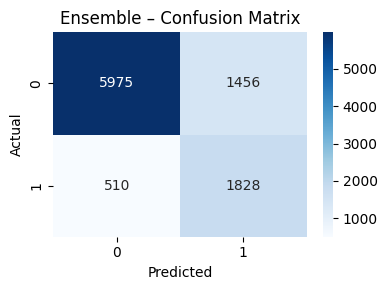

In [155]:
plt.figure(figsize=(4,3))
sns.heatmap(ensemble_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Ensemble – Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [156]:
# Compare the ensemble against the individual tuned models:

In [157]:
comparison_rows = []

for name, model in [
    ("KNN (CV-tuned)", final_knn),
    ("Decision Tree (CV-tuned)", final_tree),
    ("Naive Bayes", nb_reduced),
    ("Ensemble (soft voting)", ensemble),
]:
    y_pred = model.predict(X_test_reduced)
    acc = accuracy_score(y_test, y_pred)
    comparison_rows.append({"Model": name, "Test Accuracy": acc})

ensemble_comparison = pd.DataFrame(comparison_rows)
ensemble_comparison

,Model,Test Accuracy
0,KNN (CV-tuned),0.828539
1,Decision Tree (CV-tuned),0.834272
2,Naive Bayes,0.685331
3,Ensemble (soft voting),0.798751
